# Day 2

Today, we will start using nf-core pipelines to find differentially abundant genes in our dataset. 
We are using data from the following paper: https://www.nature.com/articles/s41593-023-01350-3#Sec10

1. Please take some time to read through the paper and understand their approach, hypotheses and goals.

What was the objective of the study?

The study aimed to understand how chronic oxycodone exposure and subsequent withdrawal change gene expression in the brain reward circuitry (nucleus accumbens, medial prefrontal cortex and ventral tegmental area) of mice, with and without chronic neuropathic pain (spared nerve injury). 

What do the conditions mean?

oxy: oxycodone: Oxycodone HCl (Sigma-Aldrich) was diluted in 0.9% sterile saline and was administered 9 weeks after surgery, subcutaneously once a day at 30 mg per kg body weight for 2 weeks. This was followed by allowed spontaneously withdrawal for 21 days.


sal: saline: Saline injections were administered at the same time and with the same schedule as oxycodone, and up to 21 d after cessation of opioid treatment for HDAC inhibitor studies.

What do the genotypes mean?

SNI: Mice with prolonged spared nerve injury (chronic pain states), caused by surgery at the sciatic nerve.


Sham: Control mice with the same surgery, but the nerves were left untouched.

Imagine you are the bioinformatician in the group who conducted this study. They hand you the raw files and ask you to analyze them.

What would you do? 
I would process the raw sequencing data as follows: Quality control (QC), read alignment, quantification, normalization, and differential expression analysis.

Which groups would you compare to each other?
1. Sham-Oxy vs Sham-Sal (Effect of oxycodone withdrawal alone without chronic pain)
2. SNI-Oxy vs SNI-Sal  (Effect of oxycodone withdrawal with chronic pain)
3. SNI-Sal vs Sham-Sal (Effect of chronic pain alone)
4. SNI-Oxy vs Sham-Oxy (Effect of chronic pain on oxycodone withdrawal)
5. SNI-Oxy vs Sham-Sal (Combined effect: pain + withdrawal vs. control group)

Please also mention which outcome you would expect to see from each comparison. 
1. Transcriptomic changes in the reward pathways associated with oxycodone withdrawal alone, in the absence of chronic pain.
2. Transcriptomic modulation during oxycodone withdrawal in the presence of chronic neuropathic pain, highlighting differences compared to withdrawal without pain.
3. An isolated transcriptomic signature of chronic peripheral nerve injury.
4. A specific impact of underlying chronic pain during the withdrawal state, revealing pain-induced transcriptional alterations that exacerbate oxycodone dependency mechanisms.
5. Maximal transcriptomic divergence and highest number of differentially expressed genes, reflecting the combined cumulative stress of both chronic pain and oxycodone withdrawal compared to the control.

In [5]:
import pandas as pd 

Your group gave you a very suboptimal excel sheet (conditions_runs_oxy_project.xlsx) to get the information you need for each run they uploaded to the SRA.<br>
So, instead of directly diving into downloading the data and starting the analysis, you first need to sort the lazy table.<br>
Use Python and Pandas to get the table into a more sensible order.<br>
Then, perform some overview analysis and plot the results
1. How many samples do you have per condition? 8
2. How many samples do you have per genotype?  8
3. How often do you have each condition per genotype? Each condition 4 times per genotype

In [6]:
df = pd.read_excel("conditions_runs_oxy_project.xlsx")
df.head()

,Patient,Run,RNA-seq,DNA-seq,condition: Sal,Condition: Oxy,Genotype: SNI,Genotype: Sham
0,?,SRR23195505,x,NaN,x,NaN,x,NaN
1,?,SRR23195506,x,NaN,NaN,x,NaN,x
2,?,SRR23195507,x,NaN,x,NaN,NaN,x
3,?,SRR23195508,x,NaN,NaN,x,x,NaN
4,?,SRR23195509,x,NaN,NaN,x,x,NaN


In [7]:
print(df.columns.tolist())


['Patient', 'Run', 'RNA-seq', 'DNA-seq', 'condition: Sal', 'Condition: Oxy', 'Genotype: SNI', 'Genotype: Sham']


In [8]:
#Sorting the table
def pick(row, mapping):
    for col, label in mapping.items():
        if str(row[col]).strip().lower() == "x":
            return label

cond_map = {"condition: Sal": "Sal", "Condition: Oxy": "Oxy"}
geno_map = {"Genotype: SNI": "SNI", "Genotype: Sham": "Sham"}

tidy = pd.DataFrame({
    "run": df["Run"],
    "condition": df.apply(pick, axis=1, mapping=cond_map),
    "genotype": df.apply(pick, axis=1, mapping=geno_map),
})
tidy

,run,condition,genotype
0,SRR23195505,Sal,SNI
1,SRR23195506,Oxy,Sham
2,SRR23195507,Sal,Sham
3,SRR23195508,Oxy,SNI
4,SRR23195509,Oxy,SNI
5,SRR23195510,Sal,SNI
6,SRR23195511,Oxy,Sham
7,SRR23195512,Sal,Sham
8,SRR23195513,Sal,SNI
9,SRR23195514,Oxy,Sham


In [9]:
print(tidy["condition"].value_counts())             
print(tidy["genotype"].value_counts())             
print(pd.crosstab(tidy["condition"], tidy["genotype"]))

condition
Sal    8
Oxy    8
Name: count, dtype: int64
genotype
SNI     8
Sham    8
Name: count, dtype: int64
genotype   SNI  Sham
condition           
Oxy          4     4
Sal          4     4


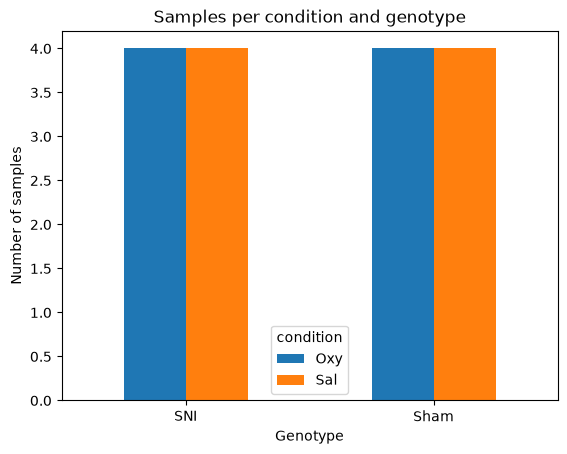

In [11]:
# Plotting the results
%matplotlib inline
import matplotlib.pyplot as plt

pd.crosstab(tidy["genotype"], tidy["condition"]).plot(kind="bar")
plt.ylabel("Number of samples")
plt.xlabel("Genotype")
plt.title("Samples per condition and genotype")
plt.xticks(rotation=0)
plt.show()

They were so kind to also provide you with the information of the number of bases per run, so that you can know how much space the data will take on your Cluster.<br>
 Add a new column to your fancy table with this information (base_counts.csv) and sort your dataframe according to this information and the condition.

Then select the 2 smallest runs from your dataset and download them from SRA (maybe an nf-core pipeline can help here?...)

In [12]:
basecounts_df = pd.read_csv("base_counts.csv")
df_merged = pd.merge(df, basecounts_df, on='Run', how='left')
display(df_merged.head())

df_sorted = df_merged.sort_values(by=['Bases', 'condition: Sal', 'Condition: Oxy'], ascending=True)
display(df_sorted)

smallest_runs = df_sorted.head(2)
display(smallest_runs['Run'])

smallest_runs[['Run']].to_csv("ids.csv", index=False, header=False)

,Patient,Run,RNA-seq,DNA-seq,condition: Sal,Condition: Oxy,Genotype: SNI,Genotype: Sham,Bases
0,?,SRR23195505,x,NaN,x,NaN,x,NaN,6922564500
1,?,SRR23195506,x,NaN,NaN,x,NaN,x,7859530800
2,?,SRR23195507,x,NaN,x,NaN,NaN,x,8063298900
3,?,SRR23195508,x,NaN,NaN,x,x,NaN,6927786900
4,?,SRR23195509,x,NaN,NaN,x,x,NaN,7003550100


,Patient,Run,RNA-seq,DNA-seq,condition: Sal,Condition: Oxy,Genotype: SNI,Genotype: Sham,Bases
11,?,SRR23195516,x,NaN,NaN,x,x,NaN,6203117700
6,?,SRR23195511,x,NaN,NaN,x,NaN,x,6456390900
12,?,SRR23195517,x,NaN,NaN,x,x,NaN,6863840400
0,?,SRR23195505,x,NaN,x,NaN,x,NaN,6922564500
3,?,SRR23195508,x,NaN,NaN,x,x,NaN,6927786900
14,?,SRR23195519,x,NaN,NaN,x,NaN,x,6996050100
4,?,SRR23195509,x,NaN,NaN,x,x,NaN,7003550100
9,?,SRR23195514,x,NaN,NaN,x,NaN,x,7226808600
5,?,SRR23195510,x,NaN,x,NaN,x,NaN,7377388500
7,?,SRR23195512,x,NaN,x,NaN,NaN,x,7462857900


11    SRR23195516
6     SRR23195511
Name: Run, dtype: str

#Downloading the 2 smallest runs from SRA
nextflow run nf-core/fetchngs -r 1.13.0 -profile docker --input ids.csv --outdir fetchngs_out

While your files are downloading, get back to the paper and explain how you would try to reproduce the analysis.<br>
When you are done with this shout, so we can discuss the different ideas.

To reproduce the analysis of the paper as closely as possible, I would download the raw RNA-seq data for all runs of the study from the SRA using nf-core/fetchngs. Next, I would process it with the nf-core/rnaseq pipeline, using HISAT2 as aligner as in the paper (featureCounts would replace HTSeq), and the reference versions given in the methods. I would test for differentially expressed genes between conditions using nf-core/differentialabundance (which uses DESeq2), applying the same cutoffs as in the paper. Afterwards I would run a pathway analysis with Ingenuity Pathway Analysis (IPA), keeping in mind that it is commercial software, which could limit reproducibility. Finally, I would compare the number of differentially expressed genes per comparison and the most significant pathways with the results reported in the paper.